<a href="https://colab.research.google.com/github/Dandanzzi/Biomni/blob/main/lec14_15_BBBP_linear_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBBP 예측 (4): 선형회귀와 로지스틱 회귀

**학습 목표**: 지난 실습까지는 이웃(KNN)과 나무(Decision Tree, Random Forest)로 BBB 투과를 예측했습니다.

이번 시간에는 **입력 X와 결과 Y의 관계를 하나의 식으로 예측하는 모델**을 배웁니다.

이런 모델을 회귀(regression)라고 합니다. Y가 연속된 값이면 **선형회귀**, Y가 0 또는 1이면 **로지스틱 회귀**를 씁니다.

BBB 투과는 투과(1)/비투과(0)이므로 로지스틱 회귀로 예측하게 됩니다.

| 강의 내용 | 이 노트북 |
|---|---|
| lec14 · 선형회귀, 최소제곱법 | 2장 |
| lec15 · 선형회귀로 범주를 예측할 때의 문제 | 3장 |
| lec15 · 로지스틱 함수, 오즈, 오즈비, 경사하강법 | 4장 |
| lec15 · 다중 로지스틱 회귀 | 5장 |

**사용 데이터**: `train.csv`, `val.csv`, `test.csv`, `sample_submission.csv`
- `target=1`: BBB 투과 / `target=0`: BBB 비투과

Colab에서 **런타임 → 모두 실행** 또는 위에서부터 셀을 차례로 실행하세요.

## 0. 환경 준비

Colab에서 RDKit을 설치합니다.

In [1]:
!pip install -q rdkit

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, matthews_corrcoef, confusion_matrix)

RDLogger.DisableLog("rdApp.*")
SEED = 42  # 같은 데이터와 설정에서 결과를 다시 재현하기 위한 숫자

## 1. 데이터와 descriptor 만들기

아래 셀에서 파일 선택 창이 나타나면 네 파일을 한꺼번에 업로드합니다.
이미 Colab의 현재 폴더에 있다면 업로드를 건너뜁니다.

In [4]:
file_names = ["train.csv", "val.csv", "test.csv", "sample_submission.csv"]
missing = [name for name in file_names if not os.path.exists(name)]

if missing:
    from google.colab import files
    print("다음 파일을 업로드하세요:", missing)
    files.upload()

train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("train:", train.shape, "val:", val.shape, "test:", test.shape)
display(train.head())
print("정답별 개수")
print(train["target"].value_counts().sort_index())

다음 파일을 업로드하세요: ['train.csv', 'val.csv', 'test.csv', 'sample_submission.csv']


Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving val.csv to val.csv
Saving train.csv to train.csv
train: (1421, 3) val: (203, 2) test: (406, 2)


,sample_id,SMILES,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
1,train_0002,COC(=O)[C@@]1(O)CC[C@H]2C3CCC(=O)C4C(=O)C=CC4(...,1
2,train_0003,CN(C)CCc1ccccn1,1
3,train_0004,CC(C)NCC(O)COc1ccc(CC(N)=O)cc1,0
4,train_0005,O=C(Nc1ccc(O)cc1)C(Cl)(Cl)Cl,1


정답별 개수
target
0     341
1    1080
Name: count, dtype: int64


회귀 모델은 숫자만 입력으로 받습니다. SMILES(분자 구조 문자열)를 RDKit **descriptor**(분자 하나의 성질을 요약한 숫자)로 바꿉니다.

lec12 실습과 같은 방법으로 **RDKit이 제공하는 descriptor를 전부 계산한 뒤, 값이 제대로 나오지 않는 것만 뺍니다.**
어떤 분자에서는 값이 `NaN`(값 없음)이나 무한대가 나옵니다. descriptor에서 0은 "그 성질이 0"이라는 의미 있는 값이라
`NaN`을 0으로 채우면 데이터가 왜곡됩니다. 그래서 **train·val·test 어디에도 `NaN`이 없는 descriptor만 남깁니다.**

In [5]:
# SMILES를 분자 객체로 바꾸고, 읽을 수 없는 것이 있는지 확인합니다.
for name, data in [("train", train), ("val", val), ("test", test)]:
    data["mol"] = data["SMILES"].apply(Chem.MolFromSmiles)
    print(f"{name}: 변환 실패 {data['mol'].isna().sum()}개")

train: 변환 실패 0개
val: 변환 실패 0개
test: 변환 실패 0개


In [6]:
DESC_FUNCS = dict(Descriptors.descList)   # {descriptor 이름: 계산 함수}
ALL_NAMES = list(DESC_FUNCS)              # descriptor 이름 전체

def make_descriptors(molecules):
    """분자 목록을 descriptor 표로 바꿉니다."""
    rows = []
    for mol in molecules:
        values = []
        for name in ALL_NAMES:
            values.append(DESC_FUNCS[name](mol))
        rows.append(values)
    return pd.DataFrame(rows, columns=ALL_NAMES).astype(float)

# train/val/test 모두 전체 descriptor를 계산합니다. (1 ~ 2분 걸립니다)
desc_train_all = make_descriptors(train["mol"])
desc_val_all = make_descriptors(val["mol"])
desc_test_all = make_descriptors(test["mol"])

# 무한대를 먼저 NaN으로 바꿉니다.
desc_train_all = desc_train_all.replace([np.inf, -np.inf], np.nan)
desc_val_all = desc_val_all.replace([np.inf, -np.inf], np.nan)
desc_test_all = desc_test_all.replace([np.inf, -np.inf], np.nan)

# 세 데이터 어디에도 NaN이 없는 descriptor만 남깁니다.
keep = desc_train_all.notna().all() & desc_val_all.notna().all() & desc_test_all.notna().all()
DESCRIPTORS = desc_train_all.columns[keep].tolist()

desc_train = desc_train_all[DESCRIPTORS]
desc_val = desc_val_all[DESCRIPTORS]
desc_test = desc_test_all[DESCRIPTORS]

y = train["target"].to_numpy()   # 정답 (0 또는 1)

print("descriptor:", len(ALL_NAMES), "개 중", len(DESCRIPTORS), "개 사용 /", desc_train.shape)

# descriptor가 많으므로 잘 알려진 것 몇 개만 봅니다.
KEY_DESCRIPTORS = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors"]
display(desc_train[KEY_DESCRIPTORS].head(5).round(2))

descriptor: 217 개 중 209 개 사용 / (1421, 209)


,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors
0,197.19,0.05,103.78,4.0,4.0
1,376.45,1.43,100.90,2.0,6.0
2,150.22,1.19,16.13,0.0,2.0
3,266.34,0.45,84.58,3.0,4.0
4,254.50,2.70,49.33,2.0,2.0


# 2장. 선형회귀 (Linear regression)

선형회귀는 **Y가 연속형일 때** 사용합니다. BBB 투과(0/1)는 범주형이라 바로 쓸 수 없으므로,
먼저 **연속형 값끼리** 직선을 하나 그어 봅니다.

강의의 "나이 → 혈압" 예시 대신 분자의 **TPSA(극성 표면적)로 MolLogP(지용성)를 예측**합니다.
둘 다 BBB 투과와 관련이 큰 성질이고, 극성 표면적이 넓은 분자일수록 기름에 덜 녹을 것이라고 기대할 수 있습니다.

$$ Y = \beta_0 + \beta_1 X + \varepsilon $$

| 기호 | 이 실습에서 |
|---|---|
| X (입력변수) | TPSA |
| Y (출력변수) | MolLogP |
| $\beta_0$ | 절편 |
| $\beta_1$ | 기울기 (TPSA가 1 늘 때 MolLogP 평균의 변화량) |
| $\varepsilon$ | 오차 (X로 설명되지 않는 부분) |

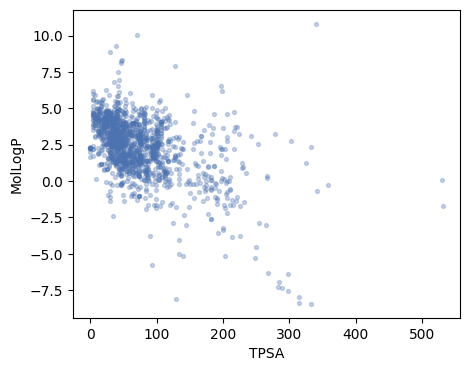

In [7]:
x_tpsa = desc_train["TPSA"].to_numpy()           # 입력변수 X
y_logp = desc_train["MolLogP"].to_numpy()   # 출력변수 Y

plt.figure(figsize=(5, 4))
plt.scatter(x_tpsa, y_logp, s=8, alpha=0.3, color="#4C72B0")
plt.xlabel("TPSA")
plt.ylabel("MolLogP")
plt.show()

## 2-1. 최소제곱법으로 직선 구하기

점들을 가장 잘 지나는 직선은 **점과 직선 사이의 거리(오차)의 제곱합이 가장 작은** 직선입니다.
이 제곱합이 비용함수(Cost function)입니다.

$$ C(\beta_0, \beta_1) = \sum_{i=1}^{n} \{ Y_i - (\beta_0 + \beta_1 X_i) \}^2 $$

비용함수는 아래로 볼록(convex)한 그릇 모양이라 최솟값이 하나뿐입니다.
그래서 미분해서 0이 되는 지점을 풀면 강의에서 본 해가 바로 나옵니다.

$$ \hat{\beta_1} = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sum (X_i - \bar{X})^2}, \qquad \hat{\beta_0} = \bar{Y} - \hat{\beta_1} \bar{X} $$

이 식을 그대로 계산해 보고, `sklearn`의 결과와 같은지 확인합니다.

In [8]:
x_mean = x_tpsa.mean()
y_mean = y_logp.mean()

b1 = np.sum((x_tpsa - x_mean) * (y_logp - y_mean)) / np.sum((x_tpsa - x_mean) ** 2)
b0 = y_mean - b1 * x_mean

print("직접 계산: 기울기 b1 =", round(b1, 4), ", 절편 b0 =", round(b0, 4))

X_tpsa = desc_train[["TPSA"]]
linear = LinearRegression()
linear.fit(X_tpsa, y_logp) # 모델이 학습

print("sklearn  : 기울기 b1 =", round(linear.coef_[0], 4),
      ", 절편 b0 =", round(linear.intercept_, 4))
print()
print(f"회귀식: MolLogP = {b0:.3f} + ({b1:.4f}) x TPSA")

직접 계산: 기울기 b1 = -0.0175 , 절편 b0 = 3.6481
sklearn  : 기울기 b1 = -0.0175 , 절편 b0 = 3.6481

회귀식: MolLogP = 3.648 + (-0.0175) x TPSA


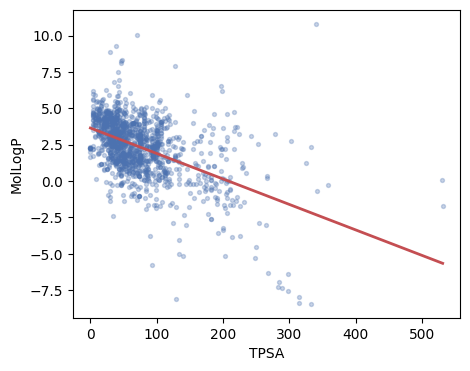

In [9]:
# 구한 직선을 점 위에 그려 봅니다.
line_x = np.array([x_tpsa.min(), x_tpsa.max()])
line_y = b0 + b1 * line_x

plt.figure(figsize=(5, 4))
plt.scatter(x_tpsa, y_logp, s=8, alpha=0.3, color="#4C72B0")
plt.plot(line_x, line_y, color="#C44E52", linewidth=2)
plt.xlabel("TPSA")
plt.ylabel("MolLogP")
plt.show()

## 2-2. 선형회귀모델의 가정

$$ y = \beta_0 + \beta_1 x + \varepsilon, \qquad \varepsilon_i \sim N(0, \sigma^2) $$

| 가정 | 내용 |
|---|---|
| 선형성 | $E(Y)$가 X의 선형식 $\beta_0 + \beta_1 X$이다 |
| 독립성 | 오차 $\varepsilon_i$는 서로 독립이다 |
| 정규성 | 오차가 정규분포를 따른다 |
| 등분산성 | 모든 X에서 오차의 분산이 $\sigma^2$으로 같다 |

$\varepsilon_i \sim N(0, \sigma^2)$ 표기는 정규성과 등분산성을 함께 나타내고, 독립성은 따로 가정합니다.

# 3장. 0과 1을 선형회귀로 예측하면?

2장에서 Y는 MolLogP처럼 **연속된 값**이었습니다. 그런데 우리가 진짜 맞혀야 하는 `target`은 **0 또는 1**뿐입니다.

이것을 그냥 숫자로 보고 직선을 그으면 어떻게 될까요?

X는 BBB 투과와 관련이 큰 TPSA를 쓰고, Y 자리에 0/1을 그대로 넣습니다.
직선이 나오면 그 값을 "투과할 확률"로 읽는 것이 목적입니다. 확률이라면 반드시 0과 1 사이여야 합니다.

예측값의 최솟값: -0.97
예측값의 최댓값: 1.036
0보다 작은 예측: 17 개
1보다 큰 예측  : 51 개


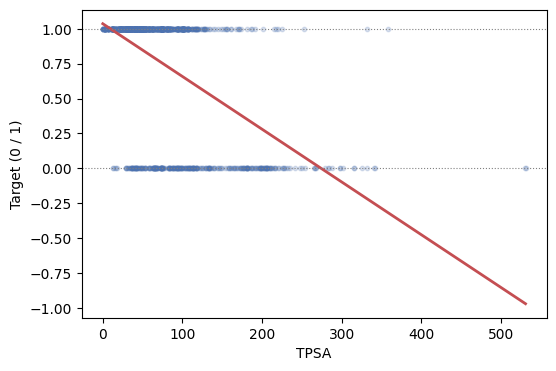

In [10]:
linear = LinearRegression()
linear.fit(X_tpsa, y)        # Y 자리에 0/1 정답을 그대로 넣습니다

# 확인 1: 예측값이 확률처럼 0~1 안에 들어오는지
pred_bbb = linear.predict(X_tpsa)
print("예측값의 최솟값:", round(pred_bbb.min(), 3))
print("예측값의 최댓값:", round(pred_bbb.max(), 3))
print("0보다 작은 예측:", int((pred_bbb < 0).sum()), "개")
print("1보다 큰 예측  :", int((pred_bbb > 1).sum()), "개")

# 확인 2: TPSA 전체 구간에 직선을 그려 어디까지 올라가고 내려가는지 봅니다.
grid = np.linspace(x_tpsa.min(), x_tpsa.max())
grid_table = pd.DataFrame({"TPSA": grid})

plt.figure(figsize=(6, 4))
plt.scatter(x_tpsa, y, s=10, alpha=0.2, color="#4C72B0")
plt.plot(grid, linear.predict(grid_table), color="#C44E52", linewidth=2)
plt.axhline(0, color="gray", linewidth=0.8, linestyle=":")
plt.axhline(1, color="gray", linewidth=0.8, linestyle=":")
plt.xlabel("TPSA")
plt.ylabel("Target (0 / 1)")
plt.show()

선형회귀는 예측값을 0과 1 사이로 제한하지 않으므로, 입력값에 따라 0보다 작거나 1보다 큰 값을 예측할 수 있습니다. 따라서 예측값을 확률로 해석하는 데 한계가 있습니다.

원인은 직선의 성질 그 자체입니다. 직선은 X가 커지면 **끝없이 올라가고 작아지면 끝없이 내려갑니다**.
반면 우리가 원하는 답은 0과 1 사이에만 있어야 합니다.

필요한 것은 **어떤 X를 넣어도 값이 0과 1 사이를 벗어나지 않는 S자 곡선**입니다. 이것이 로지스틱 회귀입니다.

# 4장. 로지스틱 회귀 (Logistic regression)

$$ \pi(X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X)}} $$

괄호 안 $\beta_0 + \beta_1 X$의 범위는 $-\infty \sim \infty$이지만 함수값은 항상 0과 1 사이입니다.

`LogisticRegression`은 사용법이 `LinearRegression`과 거의 같고,
예측은 `predict_proba`로 **확률**을 받는다는 점만 다릅니다.

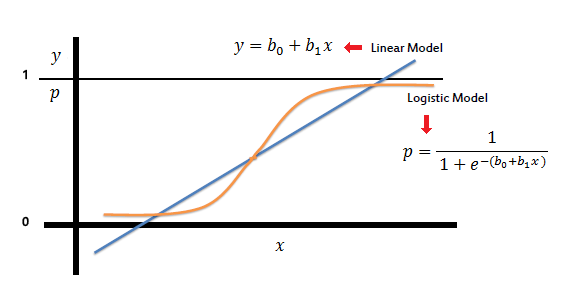

출처: https://saedsayad.com/logistic_regression.htm

b0 = 3.1631
b1 = -0.0245
확률이 0.5가 되는 TPSA = 129.0


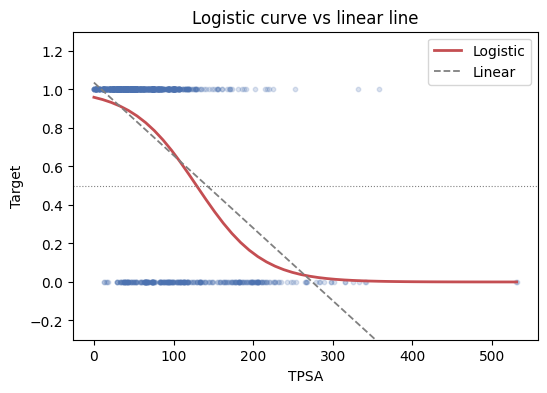

In [11]:
logit = LogisticRegression(max_iter=1000)  # max_iter: 최적화 알고리즘의 최대 반복 횟수
logit.fit(X_tpsa, y)

b0_logit = logit.intercept_[0]
b1_logit = logit.coef_[0][0]

print("b0 =", round(b0_logit, 4))
print("b1 =", round(b1_logit, 4))
print("확률이 0.5가 되는 TPSA =", round(-b0_logit / b1_logit, 1))

# 로지스틱 곡선과 3장의 직선을 같이 그려 비교합니다.
plt.figure(figsize=(6, 4))
plt.scatter(x_tpsa, y, s=10, alpha=0.2, color="#4C72B0")
plt.plot(grid, logit.predict_proba(grid_table)[:, 1],
         color="#C44E52", linewidth=2, label="Logistic")
plt.plot(grid, linear.predict(grid_table),
         color="gray", linewidth=1.3, linestyle="--", label="Linear")
plt.axhline(0.5, color="gray", linewidth=0.8, linestyle=":")
plt.ylim(-0.3, 1.3)
plt.xlabel("TPSA")
plt.ylabel("Target")
plt.title("Logistic curve vs linear line")
plt.legend()
plt.show()

로지스틱 곡선은 어떤 TPSA에서도 0 ~ 1 사이에 머뭅니다.

## 4-1. 오즈(odds)와 오즈비(odds ratio)로 $\beta_1$ 해석하기

2장 선형회귀에서는 기울기를 그대로 읽을 수 있었습니다. "TPSA가 1 늘면 MolLogP가 0.0175 줄어든다."
로지스틱에서도 똑같이 "TPSA가 1 늘면 확률이 몇 % 준다"고 말하고 싶은데, 그게 **안 됩니다**.

**오즈(odds)**는 "투과할 가능성 ÷ 투과 안 할 가능성"입니다.

$$ \text{Odds} = \frac{\pi(X)}{1 - \pi(X)} $$


| TPSA | 확률 | Odds | 앞 칸 대비 |
|---|---|---|---|
| 20 | 0.935 | 14.48 | |
| 60 | 0.844 | 5.43 | ×0.375 |
| 100 | 0.671 | 2.04 | ×0.375 |
| 140 | 0.433 | 0.76 | ×0.375 |

**배수가 일정합니다.** TPSA가 40 늘 때마다 오즈는 언제나 0.375배가 됩니다.

### 회귀계수 $\beta_1$과 오즈비의 관계

오즈에 로그를 씌우면 2장에서 본 **직선**이 됩니다. 이것을 **로짓 변환**이라고 합니다.

$$ \log(\text{Odds}) = \log \left( \frac{\pi(X)}{1 - \pi(X)} \right) = \beta_0 + \beta_1 x $$

즉 $\beta_1$은 **x가 한 단위 증가할 때 $\log(\text{Odds})$의 증가량**입니다.
양변에 지수를 취하면 오즈 자체는 이렇게 쓸 수 있고,

$$ \text{Odds}(x) = e^{\beta_0 + \beta_1 x} $$

x를 1 늘린 오즈를 원래 오즈로 **나누면** 그 배수가 나옵니다.

$$ \frac{\text{Odds}(x+1)}{\text{Odds}(x)} = \frac{e^{\beta_0 + \beta_1 (x+1)}}{e^{\beta_0 + \beta_1 x}} = e^{\beta_1} $$

이렇게 **오즈 두 개를 나눈 값**이 **오즈비(odds ratio)**입니다.
나누는 과정에서 $\beta_0$도 x도 사라지고 $e^{\beta_1}$만 남습니다.

정리하면, 선형회귀 계수는 **더하기**로 읽고 로지스틱 회귀 계수는 **곱하기**로 읽습니다.

In [12]:
# 특정 TPSA 값에서 확률과 오즈를 직접 확인합니다.
check = pd.DataFrame({"TPSA": [1, 2, 3, 11, 12, 13]})
check["확률(예측값)"] = logit.predict_proba(check[["TPSA"]])[:, 1]
check["Odds"] = check["확률(예측값)"] / (1 - check["확률(예측값)"])
display(check.round(3))

# 오즈 두 개를 직접 나눠 봅니다.
odds = check["Odds"]
print("TPSA 1 →  2 (1 증가) : 오즈비 =", round(odds[1] / odds[0], 4))
print("TPSA 2 →  3 (1 증가) : 오즈비 =", round(odds[2] / odds[1], 4))
print("TPSA 1 → 11 (10 증가): 오즈비 =", round(odds[3] / odds[0], 4))
print("TPSA 3 → 13 (10 증가): 오즈비 =", round(odds[5] / odds[2], 4))
print()
print("공식과 비교:  e^(b1)      =", round(np.exp(b1_logit), 4))
print("           e^(b1 * 10) =", round(np.exp(b1_logit * 10), 4))

,TPSA,확률(예측값),Odds
0,1,0.958,23.071
1,2,0.957,22.512
2,3,0.956,21.967
3,11,0.948,18.053
4,12,0.946,17.616
5,13,0.945,17.189


TPSA 1 →  2 (1 증가) : 오즈비 = 0.9758
TPSA 2 →  3 (1 증가) : 오즈비 = 0.9758
TPSA 1 → 11 (10 증가): 오즈비 = 0.7825
TPSA 3 → 13 (10 증가): 오즈비 = 0.7825

공식과 비교:  e^(b1)      = 0.9758
           e^(b1 * 10) = 0.7825


오즈비가 1보다 작으므로 TPSA가 커질수록 투과 가능성이 줄어듭니다.
극성 표면적이 넓을수록 BBB를 잘 통과하지 못한다는 알려진 사실과 방향이 같습니다.

## 4-2. 경사하강법으로 파라미터 찾기

선형회귀는 미분 = 0을 **식으로 풀 수 있었지만**, 로지스틱 회귀는 그렇지 않습니다.
그래서 기울기를 보고 조금씩 내려가는 **경사하강법**을 씁니다.

비용함수(Cost function)는 제곱오차가 아니라 **로그 비용(cross-entropy)** 입니다.
시그모이드에 제곱오차를 쓰면 비용함수가 convex가 아니어서 지역 최솟값이 생길 수 있기 때문입니다.

$$ cost = -\frac{1}{m} \sum \{ y \log(\pi(x)) + (1-y) \log(1 - \pi(x)) \} $$

**갱신 규칙**은 위 비용함수가 줄어드는 방향으로 $\beta$를 조금씩 옮기는 것입니다.

$$ \beta_j \leftarrow \beta_j - \alpha \frac{\partial\, cost}{\partial \beta_j}, \qquad
   \frac{\partial\, cost}{\partial \beta_j} = \frac{1}{m}\sum (\pi(x_i) - y_i)\, x_{ij} $$

즉 **"(예측 − 정답) × 입력"의 평균만큼 옮겨라**는 뜻입니다.

In [13]:
scaler_tpsa = StandardScaler()
x_std = scaler_tpsa.fit_transform(desc_train[["TPSA"]]).ravel() # TPSA를 평균 0, 표준편차 1로

b0 = 0.0      # 절편의 시작값
b1 = 0.0      # 기울기의 시작값
alpha = 0.5   # 학습률 : 한 번에 얼마나 움직일지

for step in range(1001):
    prob_hat = 1 / (1 + np.exp(-(b0 + b1 * x_std)))   # 예측한 확률
    error = prob_hat - y                              # 오차 = 예측 - 정답
    b0 = b0 - alpha * error.mean()
    b1 = b1 - alpha * (error * x_std).mean()

    if step % 100 == 0:
        cost_now = -np.mean(y * np.log(prob_hat) + (1 - y) * np.log(1 - prob_hat))
        print(f"step {step:5d}  cost {cost_now:.4f}  b0 {b0:.4f}  b1 {b1:.4f}")

print()
print("경사하강법 결과:", round(b0, 4), round(b1, 4))

# sklearn을 같은 조건으로 학습시켜 비교합니다.
logit_std = LogisticRegression(max_iter=1000)
logit_std.fit(pd.DataFrame({"TPSA_std": x_std}), y)
print("sklearn 결과   :", round(logit_std.intercept_[0], 4), round(logit_std.coef_[0][0], 4))

step     0  cost 0.6931  b0 0.1300  b1 -0.1098
step   100  cost 0.4187  b0 1.3640  b1 -1.4074
step   200  cost 0.4187  b0 1.3718  b1 -1.4248
step   300  cost 0.4187  b0 1.3720  b1 -1.4252
step   400  cost 0.4187  b0 1.3720  b1 -1.4252
step   500  cost 0.4187  b0 1.3720  b1 -1.4252
step   600  cost 0.4187  b0 1.3720  b1 -1.4252
step   700  cost 0.4187  b0 1.3720  b1 -1.4252
step   800  cost 0.4187  b0 1.3720  b1 -1.4252
step   900  cost 0.4187  b0 1.3720  b1 -1.4252
step  1000  cost 0.4187  b0 1.3720  b1 -1.4252

경사하강법 결과: 1.372 -1.4252
sklearn 결과   : 1.3697 -1.4129


cost가 줄어들다가 더 이상 줄지 않고, 두 결과가 거의 같은 값입니다.
직접 돌린 경사하강법이 `sklearn`이 찾은 것과 같은 자리에 도착했다는 뜻입니다.

# 5장. 다중 로지스틱 회귀로 BBB 투과 예측하기

$$ \pi(X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \cdots + \beta_p X_p)}} $$

지금까지는 X가 TPSA 하나뿐이었습니다. 이제 1장에서 추린 descriptor를 **전부** 넣습니다.

대회 `val.csv`와 구별하기 위해, train에서 따로 나눈 것을 **내부 검증 데이터**라고 부릅니다.
`stratify=y`는 두 그룹의 0과 1 비율을 비슷하게 유지합니다.

descriptor는 범위가 제각각입니다.
이대로 두면 계수의 크기를 서로 비교할 수 없으므로 **표준화**합니다.
평균과 표준편차는 **학습 데이터에서만** 계산하고, 검증 데이터에는 그 값을 그대로 적용합니다.

In [14]:
idx_fit, idx_valid = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED
)

X_fit = desc_train.iloc[idx_fit]
X_valid = desc_train.iloc[idx_valid]
y_fit = y[idx_fit]
y_valid = y[idx_valid]
print("내부 학습:", len(X_fit), "개 / 내부 검증:", len(X_valid), "개")

scaler = StandardScaler()
scaler.fit(X_fit)
X_fit_scaled = scaler.transform(X_fit)
X_valid_scaled = scaler.transform(X_valid)

logit = LogisticRegression(max_iter=1000, random_state=SEED)
logit.fit(X_fit_scaled, y_fit)

# predict_proba의 두 번째 열이 target=1(투과)일 확률입니다.
valid_prob = logit.predict_proba(X_valid_scaled)[:, 1]
df = pd.DataFrame({
    "투과(1)일 확률": valid_prob[:5],
    "정답": y_valid[:5]})
display(df.round(3))

내부 학습: 1136 개 / 내부 검증: 285 개


,투과(1)일 확률,정답
0,0.291,0
1,0.007,0
2,0.042,0
3,0.838,1
4,0.000,0


## 5-1. 성능 평가

lec12 실습에서 쓰던 지표를 그대로 씁니다. 확률을 **기준값 0.5**로 0/1로 바꾼 뒤 계산합니다.

,내부 검증 점수
Accuracy,0.881
Precision,0.896
Recall,0.954
F1,0.924
ROC-AUC,0.888
MCC,0.654


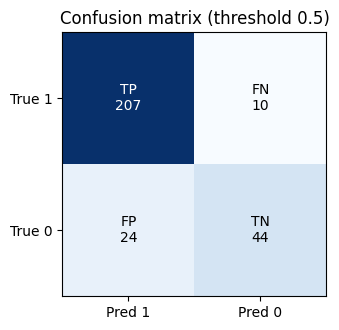

In [15]:
def evaluate(y_true, prob, threshold=0.5):
    """확률을 기준값으로 0/1로 바꾼 뒤 지표 6개를 계산합니다."""
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "MCC": matthews_corrcoef(y_true, pred),
    }

display(pd.Series(evaluate(y_valid, valid_prob)).round(3).to_frame("내부 검증 점수"))

# Confusion matrix
matrix = confusion_matrix(y_valid, (valid_prob >= 0.5).astype(int), labels=[1, 0])
names = [["TP", "FN"], ["FP", "TN"]]

plt.figure(figsize=(3.6, 3.4))
plt.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
        plt.text(j, i, f"{names[i][j]}\n{matrix[i, j]}", ha="center", va="center", color=color)
plt.xticks([0, 1], ["Pred 1", "Pred 0"])
plt.yticks([0, 1], ["True 1", "True 0"])
plt.title("Confusion matrix (threshold 0.5)")
plt.tight_layout()
plt.show()

## 5-2. fingerprint로 실습

지금까지는 입력 X가 descriptor였고, **fingerprint**로 바꿔서도 진행해봅니다.

| 입력 | 내용 |
|---|---|
| descriptor | 분자량·logP·TPSA 등 분자의 성질을 요약한 숫자 209개. 범위가 제각각이라 **표준화 필요** |
| fingerprint | 부분구조가 있으면 1, 없으면 0인 2048칸 비트열. 전부 0/1이라 **표준화 불필요** |

모델(로지스틱 회귀)은 그대로 두고 **입력 표현만** 바꿔서 같은 내부 검증 데이터로 비교합니다.

In [16]:
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def make_fingerprints(molecules):
    """분자 목록을 fingerprint 표로 바꿉니다."""
    rows = []
    for mol in molecules:
        rows.append(generator.GetFingerprintAsNumPy(mol))
    return pd.DataFrame(np.array(rows))

fp_train = make_fingerprints(train["mol"])
fp_val = make_fingerprints(val["mol"])
fp_test = make_fingerprints(test["mol"])
print("fingerprint 표 크기:", fp_train.shape)

fingerprint 표 크기: (1421, 2048)


In [17]:
# 앞에서 쓴 것과 같은 방식으로 나누고, 표준화 없이 바로 학습합니다.
logit_fp = LogisticRegression(max_iter=1000, random_state=SEED)
logit_fp.fit(fp_train.iloc[idx_fit], y_fit)
fp_prob = logit_fp.predict_proba(fp_train.iloc[idx_valid])[:, 1]

compare = pd.DataFrame({
    f"descriptor ({len(DESCRIPTORS)}개)": evaluate(y_valid, valid_prob),
    f"fingerprint ({fp_train.shape[1]}개)": evaluate(y_valid, fp_prob),
}).T
display(compare.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,MCC
descriptor (209개),0.881,0.896,0.954,0.924,0.888,0.654
fingerprint (2048개),0.895,0.905,0.963,0.933,0.932,0.696


같은 로지스틱 회귀인데 점수가 달라집니다. **입력을 어떻게 표현하느냐가 모델 선택만큼 중요합니다.**

# 6장. 전체 train으로 다시 학습하고 제출 파일 만들기

비교가 끝나면 내부 검증에 썼던 데이터까지 포함해 **전체 train**으로 다시 학습합니다.
대회 `val`, `test`의 정답은 학습에 쓰지 않습니다.

제출값은 0/1이 아니라 **BBB 투과 확률**입니다.

In [19]:
# 아래 한 줄만 5-4에서 더 좋았던 쪽으로 바꾸면 됩니다.
feature = "fingerprint"   # descriptor | fingerprint

if feature == "descriptor":
    # descriptor는 값의 범위가 제각각이라 표준화합니다.
    final_scaler = StandardScaler().fit(desc_train)
    X_train_final = final_scaler.transform(desc_train)
    X_val_final = final_scaler.transform(desc_val)
    X_test_final = final_scaler.transform(desc_test)
else:
    # fingerprint는 전부 0/1이라 표준화하지 않습니다.
    X_train_final = fp_train
    X_val_final = fp_val
    X_test_final = fp_test

print("사용할 입력:", feature, "/ feature 개수:", X_train_final.shape[1])

final_model = LogisticRegression(max_iter=1000, random_state=SEED) #반복횟수 수정을 통한 모델 예측 성능 비교
final_model.fit(X_train_final, y)

val_prob = final_model.predict_proba(X_val_final)[:, 1]
test_prob = final_model.predict_proba(X_test_final)[:, 1]
print("val 예측:", len(val_prob), "개 / test 예측:", len(test_prob), "개")

사용할 입력: fingerprint / feature 개수: 2048
val 예측: 203 개 / test 예측: 406 개


In [ ]:
val_pred = pd.DataFrame({"sample_id": val["sample_id"], "prediction": val_prob})
test_pred = pd.DataFrame({"sample_id": test["sample_id"], "prediction": test_prob})
all_pred = pd.concat([val_pred, test_pred], ignore_index=True)

# 제출 양식의 sample_id 순서에 맞춰 예측값을 붙입니다.
submission = sample_sub[["sample_id"]].merge(all_pred, on="sample_id", how="left")

print("제출 양식 행 수:", len(sample_sub), "/ 만든 제출 파일 행 수:", len(submission))
print("예측이 비어 있는 행:", submission["prediction"].isna().sum(), "개  (0이어야 합니다)")

submission.to_csv("submission_lec15.csv", index=False)
print("submission_lec15.csv 저장 완료")
display(submission.head())

제출 양식 행 수: 609 / 만든 제출 파일 행 수: 609
예측이 비어 있는 행: 0 개  (0이어야 합니다)
submission_lec15.csv 저장 완료


,sample_id,prediction
0,val_001,0.913035
1,val_002,0.999222
2,val_003,0.979003
3,val_004,0.989463
4,val_005,0.987901


In [ ]:
try:
    from google.colab import files
    files.download("submission_lec15.csv")
except ImportError:
    print("제출 파일이 현재 폴더에 저장되어 있습니다.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 확인 문제

1. 선형회귀의 비용함수는 무엇이고, 오차를 제곱하는 이유는 무엇인가요?
2. 선형회귀모델의 오차항에 대한 가정 네 가지를 쓰세요.
3. 0/1 정답에 선형회귀를 쓰면 어떤 문제가 생기나요?
4. 로지스틱 회귀의 $\beta_1$을 "X가 1 늘면 확률이 $\beta_1$만큼 는다"로 해석하면 왜 틀리나요?
5. 4-1에서 구한 TPSA의 오즈비를 해석해 보세요.
6. 로지스틱 회귀의 비용함수로 제곱오차 대신 로그 비용을 쓰는 이유는 무엇인가요?

5-4에서 더 좋았던 입력으로 `submission_lec15.csv`를 만들어 제출하세요.